In [1]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import pandas as pd
import seaborn as sns
import numpy as np
import random
import decoupler as dc
from helper import plot_ct_density
import pandas as pd

SEED = 0
np.random.seed(SEED)
random.seed(SEED)


my_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)





figure_save_path = "../results/Fig_6_figures"
os.makedirs(figure_save_path, exist_ok=True)




## Fig. 6b

In [5]:
def apply_pca(pdata):
    pdata = pdata.copy()
    pdata.layers["counts"] = pdata.X.copy()
    
    # Normalize, scale and compute pca
    sc.pp.normalize_total(pdata, target_sum=1e4)
    sc.pp.log1p(pdata)
    sc.pp.scale(pdata, max_value=10)
    sc.tl.pca(pdata)
    
    # Return raw counts to X
    dc.pp.swap_layer(adata=pdata, key="counts", inplace=True)

    return pdata

In [6]:
pdata = sc.read("../data/bulk_pca_combined_min.h5ad")
pca_pdata = apply_pca(pdata)

In [7]:
cultured_pca_pdata = pca_pdata[pca_pdata.obs['Protocol_Type'] == 'Cultured'].copy()

cultured_pca_pdata.obs['Protocol'] = pd.Categorical(
    cultured_pca_pdata.obs['Protocol'],
    categories=['WLCS', 'Negative Fraction', 'Outgrowth']
)
cultured_pca_pdata.uns['Protocol_colors'] = ["#2027c7", "#e4b075", "#cdb2ef"]

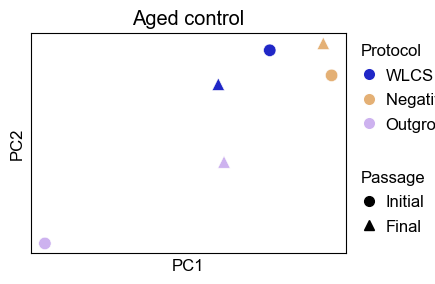

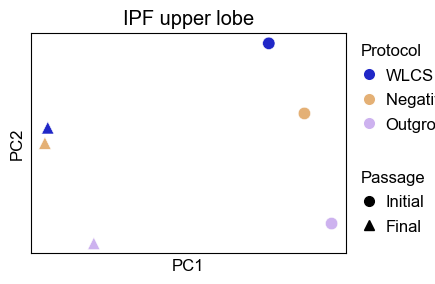

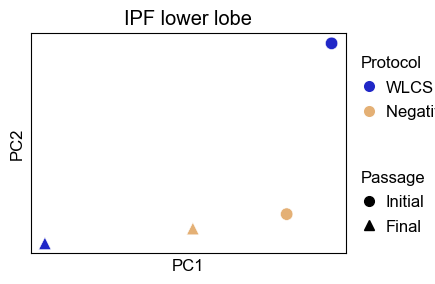

In [10]:
conditions = ['Aged control', 'IPF upper lobe', 'IPF lower lobe']

marker_map = {"Initial": "o", "Final": "^"} 

with plt.rc_context({'figure.figsize': (4.5, 3),
                     'font.size': 12,
                     'legend.fontsize': 12
                    }):

    for con in conditions:
        ad = cultured_pca_pdata[cultured_pca_pdata.obs['Condition'] == con].copy()

        protocol_categories = ad.obs["Protocol"].cat.categories
        protocol_colors = ad.uns["Protocol_colors"]
        color_map = dict(zip(protocol_categories, protocol_colors))

        plt.figure()

        for passage in ad.obs["Passage"].unique():
            ad_sub = ad[ad.obs["Passage"] == passage]

            plt.scatter(
                ad_sub.obsm["X_pca"][:, 0],
                ad_sub.obsm["X_pca"][:, 1],
                s=80,
                marker=marker_map.get(passage, "o"),
                c=[color_map[p] for p in ad_sub.obs["Protocol"]],
                edgecolor="white",
                linewidth=0.4,
            )

        plt.title(con)
        plt.xlabel("PC1")
        plt.ylabel("PC2")
        plt.xticks([])
        plt.yticks([])
        plt.gca().set_xticks([])
        plt.gca().set_yticks([])

        plt.subplots_adjust(right=0.62, bottom=0.08, left=0.05, top=0.9)
        
        protocol_handles = [
            Line2D([0], [0], marker='o', color='w',
                   markerfacecolor=color_map[p], markersize=9,
                   label=p)
            for p in protocol_categories
        ]


        legend1 = plt.legend(
            handles=protocol_handles,
            title="Protocol",
            loc="center left",
            bbox_to_anchor=(1.02, 0.75)
        )
        plt.gca().add_artist(legend1)

        passage_handles = [
            Line2D([0], [0], marker=marker_map[p], color='black',
                   linestyle='', markersize=7,
                   label=p)
            for p in ad.obs["Passage"].unique()
        ]
        legend2 = plt.legend(
            handles=passage_handles,
            title="Passage",
            loc="center left",
            bbox_to_anchor=(1.02, 0.23)
        )

        legend1._legend_box.align = "left"
        legend1.get_title().set_fontsize(12)
        
        legend2._legend_box.align = "left"
        legend2.get_title().set_fontsize(12)

        # plt.tight_layout()
        plt.savefig(os.path.join(
            figure_save_path, f"pca_Cultured_{con.replace(' ', '_')}_ProtocolShape.pdf"))
        plt.show()

## Fig. 6c

In [7]:
adata = sc.read("../data/Cultured_fibroblasts_min.h5ad")


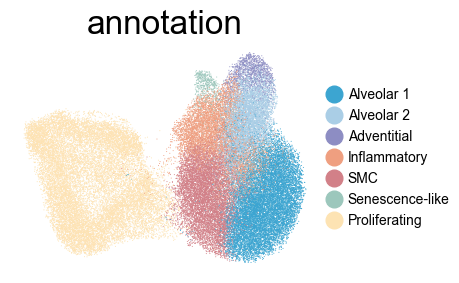

In [8]:
with plt.rc_context({'font.size': 20, 'legend.markerscale': 2.0, 'figure.figsize': (4, 3)}):
    fig = sc.pl.umap(
        adata,
        color='annotation',
        frameon=False,
        return_fig=True
    )
    fig.savefig(f'{figure_save_path}/Cultured_fibroblasts_umap.pdf', bbox_inches='tight')
    plt.show()

## Fig. 6d

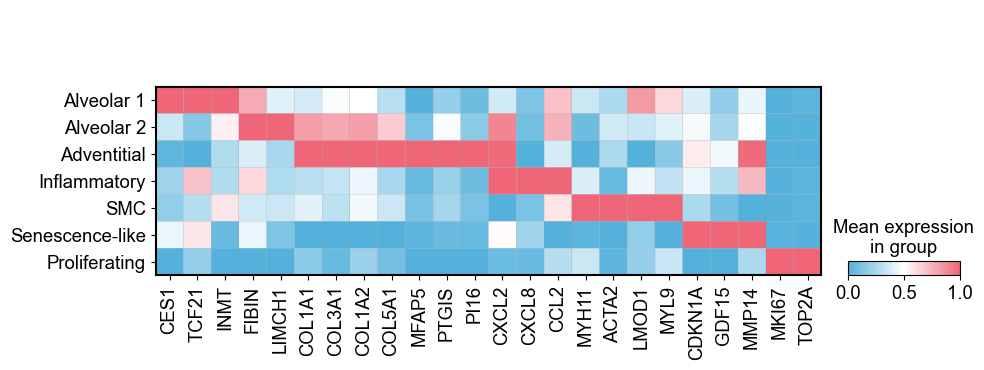

In [9]:
fibroblast_markers = {
    "Alveolar": ["CES1",  "TCF21", "INMT", "FIBIN",
                 "LIMCH1"],
    'Collagen': ['COL1A1', 'COL3A1', 'COL1A2', 'COL5A1'],
    "Adventitial": ["MFAP5", "PTGIS", "PI16"],
    "Inflammatory": ["CXCL2", "CXCL8", "CCL2"],
    "SMC": ["MYH11", "ACTA2", "LMOD1", "MYL9"],
    "Senescence-like": ["CDKN1A", "GDF15", "MMP14"],
    "Proliferating": ["MKI67", "TOP2A"],
}
fibroblast_markers_list = []
for category in fibroblast_markers.values():
    fibroblast_markers_list.extend(category)

with plt.rc_context({'font.size': 16}):
    fig = sc.pl.matrixplot(
        adata,
        var_names=fibroblast_markers_list,
        groupby='annotation',
        standard_scale='var',
        cmap=my_cmap,
        return_fig=True,
    )
    fig.savefig(f'{figure_save_path}/Cultured_fibroblasts_heatmap.pdf', bbox_inches='tight')
    plt.show()

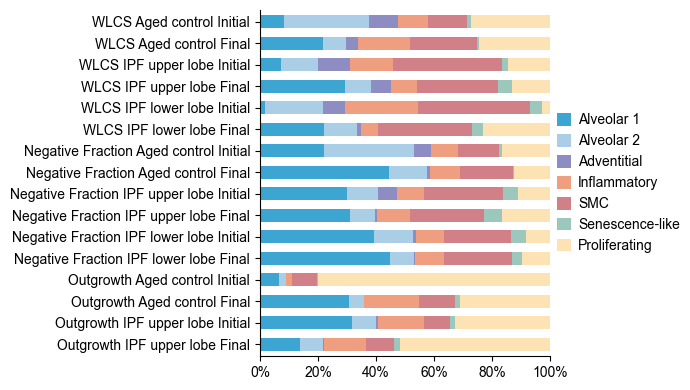

In [10]:
fig, df = plot_ct_density(adata, ct_key='annotation', group_key='Protocol_Passage_Condition', figsize=(7, 4), title="")
fig.savefig(os.path.join(figure_save_path, "Cultured_fibroblasts_proportion.pdf"), bbox_inches='tight')
plt.show()